# Task 3 missing-value EDA

คำถาม: error ที่เหลือของ V8 (champion, OOF 0.7921) ไปกองอยู่ในแถวที่ feature สำคัญหายไปหรือเปล่า

ที่มา: ใน Task 1 (`Task1/README.md` บน branch `task1-2`) ค่าว่างเป็นตัวกำหนดเพดานคะแนน และการเติมค่าว่างจาก feature อื่นโดยไม่ใช้ label ช่วยได้ ส่วน V8 ทาย `log(y / prev_month_spending)` ถ้า `prev_month_spending` หาย จะใช้ prev = 1 คือทาย `log(y)` ตรงๆ ซึ่งอาจแย่กว่ามาก

วิเคราะห์อย่างเดียว ไม่แก้โมเดล ใช้ `train.csv` + OOF ของ V8 (`experiments/task3/champion/task3_oof.csv`)

## Imports

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."


## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `baseline/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA  # ../cpe342-kaggle-main, needs ROOT on sys.path
from pis.tabular import _score       # the competition metric: 1 / (1 + sum|y - p| / sum y)
print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load data & check the V8 OOF

OOF ต้องเรียงแถวเดียวกับ `train.csv` (เช็ค `player_id`) และต้องได้ 0.7921 ตาม `champion.json` ก่อนจะเชื่อตัวเลขที่เหลือ

In [3]:
tr = pd.read_csv(DEFAULT_DATA / '03_regression' / 'train.csv')  # train
o = pd.read_csv('experiments/task3/champion/task3_oof.csv')       # V8 out-of-fold predictions
assert (tr['player_id'].to_numpy() == o['player_id'].to_numpy()).all(), 'OOF row order differs from train.csv'
assert np.allclose(tr['spending_30d'], o['target'])

y, pred = tr['spending_30d'], o['prediction']
err = (y - pred).abs()                # per-row absolute error
E, Y = err.sum(), y.sum()             # the metric is 1 / (1 + E / Y)
feats = [c for c in tr.columns if c not in ('player_id', 'spending_30d')]  # the 32 features
oof = _score(y, pred)
print(f"V8 OOF {oof:.4f} | rows {len(tr):,} | total |error| {E / 1e6:,.1f}M THB | total target {Y / 1e6:,.1f}M THB")

V8 OOF 0.7921 | rows 104,000 | total |error| 286.5M THB | total target 1,091.7M THB


## 1. Missingness overview

ดูว่าแต่ละ feature หายกี่ % และแต่ละแถวหายกี่ช่อง

In [4]:
share_missing = tr[feats].isna().mean()
print(f"share missing per feature: min {share_missing.min():.1%}, median {share_missing.median():.1%}, max {share_missing.max():.1%} "
      f"(all {len(feats)} features have missing values)")
share_missing.sort_values(ascending=False).head(5).to_frame('share missing').style.format('{:.2%}')

share missing per feature: min 5.7%, median 5.8%, max 6.0% (all 32 features have missing values)


,share missing
vip_status,5.95%
achievement_count,5.95%
cross_game_activity,5.92%
days_since_last_purchase,5.91%
sessions_per_week,5.90%


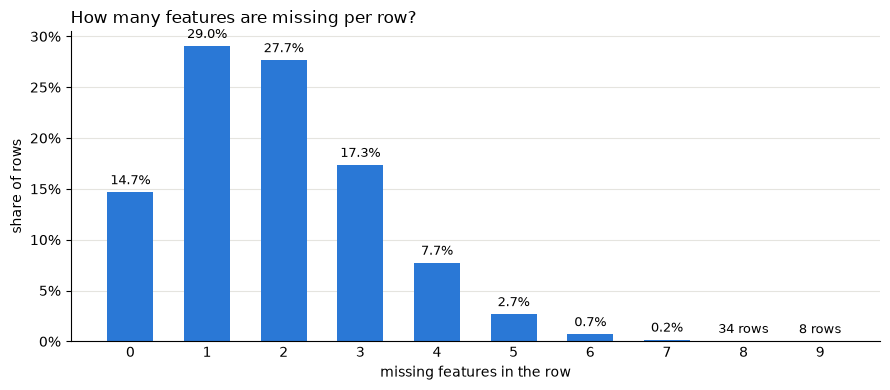

In [5]:
n_missing = tr[feats].isna().sum(axis=1)  # missing features per row
counts = n_missing.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(counts.index.astype(str), counts / len(tr), width=0.6, color='#2a78d6')
for bar, n in zip(bars, counts):
    share = n / len(tr)
    ax.text(bar.get_x() + bar.get_width() / 2, share + 0.005, f"{share:.1%}" if share >= 0.001 else f"{n} rows",
            ha='center', va='bottom', fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('missing features in the row')
ax.set_ylabel('share of rows')
ax.set_title('How many features are missing per row?', loc='left')
ax.tick_params(axis='x', length=0)
ax.grid(axis='y', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**NOTE:**

Every feature is missing in about 6% of rows, and 85% of rows miss at least one feature. Only 15% of rows are complete.

## 2. Error by feature: missing vs present

แต่ละ feature แบ่งแถวเป็น "หาย" กับ "มีค่า" แล้วเทียบ: จำนวนแถว, % คนใช้เงิน, |error| เฉลี่ย และ **สัดส่วนของ error รวม** ที่อยู่ในแถวที่หาย

- `ratio` = error share / row share: 1.0 = error กระจายตามจำนวนแถวพอดี, flag ถ้า > 1.5
- `excess` = error share − row share (หน่วย % ของ error รวม) ใช้เรียงตาราง
- `target_share` = สัดส่วนของยอดใช้จ่ายรวมในแถวที่หาย ถ้าสูงกว่า row share ก็คาด error มากกว่าปกติอยู่แล้ว (metric หารด้วยยอดรวม)
- `score_missing` / `score_present` = metric ภายในแต่ละกลุ่ม

In [6]:
rows = []
for c in feats:
    m = tr[c].isna()
    rows.append({
        'feature': c,
        'rows_missing': int(m.sum()),
        'row_share': m.mean(),
        'spenders_missing': (y[m] > 0).mean(),
        'spenders_present': (y[~m] > 0).mean(),
        'mae_missing': err[m].mean(),
        'mae_present': err[~m].mean(),
        'error_share': err[m].sum() / E,
        'target_share': y[m].sum() / Y,
        'score_missing': _score(y[m], pred[m]),
        'score_present': _score(y[~m], pred[~m]),
    })
by_feat = pd.DataFrame(rows).set_index('feature')
by_feat['ratio'] = by_feat['error_share'] / by_feat['row_share']
by_feat['excess'] = by_feat['error_share'] - by_feat['row_share']
by_feat['flag'] = np.where(by_feat['ratio'] > 1.5, 'FLAG', '')
by_feat = by_feat.sort_values('excess', ascending=False)
print(f"features flagged (ratio > 1.5): {(by_feat['flag'] == 'FLAG').sum()} of {len(by_feat)}")

pct = '{:.1%}'
(by_feat.style
    .format({'rows_missing': '{:,}', 'row_share': '{:.2%}', 'spenders_missing': pct, 'spenders_present': pct,
             'mae_missing': '{:,.0f}', 'mae_present': '{:,.0f}', 'error_share': '{:.2%}', 'target_share': '{:.2%}',
             'score_missing': '{:.4f}', 'score_present': '{:.4f}', 'ratio': '{:.2f}', 'excess': '{:+.2%}'})
    .bar(subset='ratio', color='#86b6ef', vmin=0, vmax=1.5)
    .set_caption('V8 error in rows where each feature is missing vs present, sorted by excess error'))

features flagged (ratio > 1.5): 0 of 32


,rows_missing,row_share,spenders_missing,spenders_present,mae_missing,mae_present,error_share,target_share,score_missing,score_present,ratio,excess,flag
feature,,,,,,,,,,,,,
prev_month_spending,"6,015",5.78%,52.0%,51.9%,"3,445","2,712",7.23%,5.95%,0.7582,0.7944,1.25,+1.45%,
historical_spending,"6,035",5.80%,52.1%,51.9%,"3,176","2,729",6.69%,5.68%,0.7640,0.7939,1.15,+0.89%,
avg_transaction_value,"5,991",5.76%,52.4%,51.8%,"3,125","2,732",6.54%,5.90%,0.7747,0.7933,1.13,+0.78%,
vip_status,"6,189",5.95%,51.9%,51.9%,"3,066","2,735",6.62%,5.98%,0.7748,0.7933,1.11,+0.67%,
days_since_last_login,"6,035",5.80%,51.8%,51.9%,"2,995","2,740",6.31%,5.87%,0.7799,0.7929,1.09,+0.51%,
competitive_rank,"5,940",5.71%,51.4%,51.9%,"2,990","2,740",6.20%,5.94%,0.7850,0.7926,1.09,+0.49%,
social_interactions,"6,044",5.81%,52.0%,51.9%,"2,964","2,742",6.25%,6.05%,0.7867,0.7925,1.08,+0.44%,
segment,"5,935",5.71%,53.2%,51.8%,"2,959","2,742",6.13%,6.20%,0.7940,0.7920,1.07,+0.42%,
account_age_days,"6,012",5.78%,51.8%,51.9%,"2,945","2,743",6.18%,5.59%,0.7751,0.7932,1.07,+0.40%,


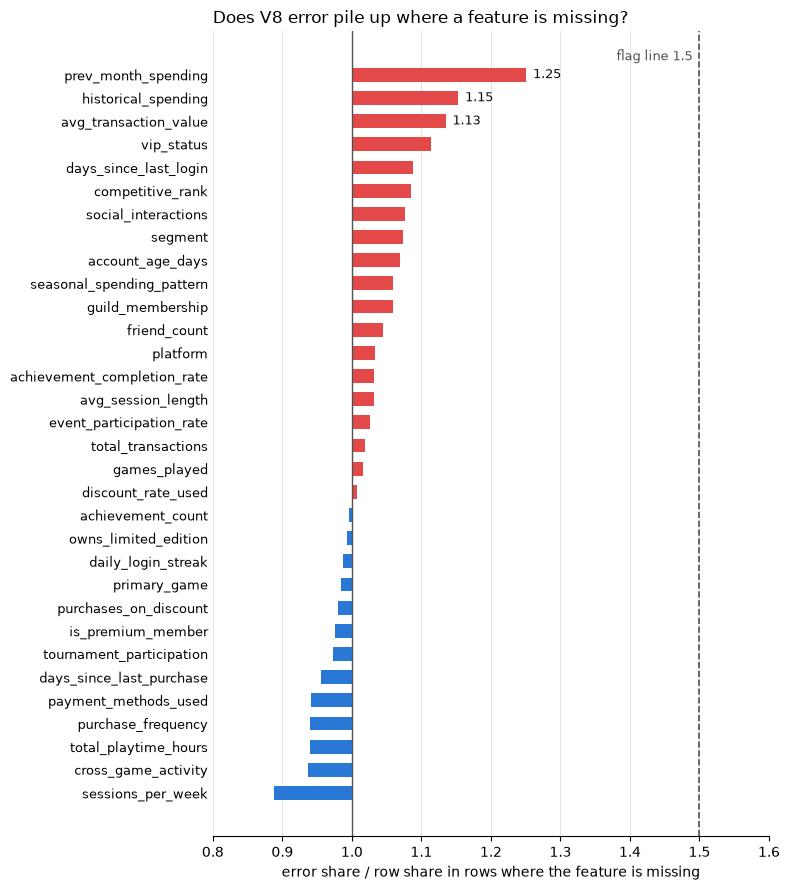

In [7]:
r = by_feat['ratio'].sort_values()  # barh draws bottom-up, so the largest ends on top
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(r.index, r.values - 1, left=1, height=0.6,
        color=['#e34948' if v > 1 else '#2a78d6' for v in r.values])  # red = more error than its row share
ax.axvline(1, color='#52514e', linewidth=1)
ax.axvline(1.5, color='#52514e', linestyle='--', linewidth=1.2)
ax.text(1.49, len(r) - 0.5, 'flag line 1.5', ha='right', va='bottom', fontsize=9, color='#52514e')
for name, v in r.tail(3).items():  # label only the top 3
    ax.text(v + 0.01, name, f"{v:.2f}", va='center', fontsize=9, color='#0b0b0b')
ax.set_xlim(0.8, 1.6)
ax.set_xlabel('error share / row share in rows where the feature is missing')
ax.set_title('Does V8 error pile up where a feature is missing?', loc='left')
ax.grid(axis='x', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=9)
plt.tight_layout()
plt.show()

**NOTE:**

No feature reaches the 1.5 flag line. The top three are all spend history: `prev_month_spending` (1.25), `historical_spending` (1.15), `avg_transaction_value` (1.13). The share of spenders is the same whether a feature is missing or not (about 52% both ways), which matches the first EDA: missingness is not linked to the target.

Part of the excess is target mix, not model error: rows missing `prev_month_spending` hold 5.95% of total spend on 5.78% of rows.

## 3. Error by number of missing features per row

ใน Task 1 แถวที่หายหลายช่องคะแนนตกชัด ดูว่า Task 3 เป็นแบบเดียวกันไหม

In [8]:
group = pd.cut(n_missing, [-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+'])
g = pd.DataFrame({'y': y, 'pred': pred, 'err': err, 'group': group}).groupby('group', observed=True)
by_count = pd.DataFrame({
    'rows': g.size(),
    'row_share': g.size() / len(tr),
    'spenders': g['y'].apply(lambda s: (s > 0).mean()),
    'mae': g['err'].mean(),
    'error_share': g['err'].sum() / E,
    'target_share': g['y'].sum() / Y,
    'score': g.apply(lambda d: _score(d['y'], d['pred'])),
})
by_count['ratio'] = by_count['error_share'] / by_count['row_share']
by_count.index.name = 'missing features'
(by_count.style
    .format({'rows': '{:,}', 'row_share': '{:.1%}', 'spenders': '{:.1%}', 'mae': '{:,.0f}', 'error_share': '{:.1%}',
             'target_share': '{:.1%}', 'score': '{:.4f}', 'ratio': '{:.2f}'})
    .set_caption('V8 error by number of missing features per row'))

,rows,row_share,spenders,mae,error_share,target_share,score,ratio
missing features,,,,,,,,
0,"15,250",14.7%,52.1%,"2,660",14.2%,14.8%,0.7991,0.97
1,"30,206",29.0%,51.7%,"2,610",27.5%,28.9%,0.7999,0.95
2,"28,757",27.7%,52.0%,"2,883",28.9%,27.8%,0.7855,1.05
3+,"29,787",28.6%,51.8%,"2,825",29.4%,28.6%,0.7874,1.03


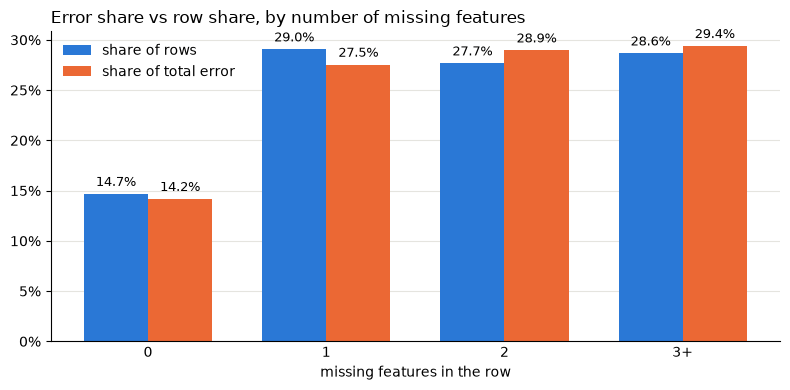

In [9]:
x = np.arange(len(by_count))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.18, by_count['row_share'], width=0.36, color='#2a78d6', label='share of rows')
ax.bar(x + 0.18, by_count['error_share'], width=0.36, color='#eb6834', label='share of total error')
for i, (rs, es) in enumerate(zip(by_count['row_share'], by_count['error_share'])):
    ax.text(i - 0.18, rs + 0.005, f"{rs:.1%}", ha='center', va='bottom', fontsize=9)
    ax.text(i + 0.18, es + 0.005, f"{es:.1%}", ha='center', va='bottom', fontsize=9)
ax.set_xticks(x, by_count.index)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('missing features in the row')
ax.set_title('Error share vs row share, by number of missing features', loc='left')
ax.legend(frameon=False, loc='upper left')
ax.tick_params(axis='x', length=0)
ax.grid(axis='y', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**NOTE:**

Error share follows row share in every group (ratio 0.95–1.05). Unlike Task 1, rows with more missing features are not clearly worse, so missingness does not cap the score here.

## 4. Focus: `prev_month_spending` missing

V8 ทาย `log(y / prev)` ถ้า prev หายจะใช้ prev = 1 (มี flag `prev_missing` บอกโมเดล) เทียบ target ของสองกลุ่ม และคะแนน V8 ภายในกลุ่ม

กลุ่มที่หายมีแค่ ~6,000 แถว และ target มีหางยาว คะแนนในกลุ่มเล็กจึงแกว่งได้เยอะ เลยเทียบกับคะแนนของแถวที่สุ่มมาจำนวนเท่ากัน 2,000 ครั้งด้วย

In [10]:
prev_missing = tr['prev_month_spending'].isna()

def describe(m):
    t = y[m]
    return {'rows': int(m.sum()), 'zero_share': (t == 0).mean(), 'median': t.median(),
            'median_if_spends': t[t > 0].median(), 'share_over_20k': (t > 20000).mean(), 'mean': t.mean(),
            'error_per_THB': err[m].sum() / t.sum(), 'V8_score': _score(t, pred[m])}

focus = pd.DataFrame({'prev missing': describe(prev_missing), 'prev present': describe(~prev_missing)}).T
(focus.style
    .format({'rows': '{:,.0f}', 'zero_share': '{:.1%}', 'median': '{:,.0f}', 'median_if_spends': '{:,.0f}',
             'share_over_20k': '{:.1%}', 'mean': '{:,.0f}', 'error_per_THB': '{:.3f}', 'V8_score': '{:.4f}'})
    .set_caption('Target and V8 score: prev_month_spending missing vs present (THB)'))

,rows,zero_share,median,median_if_spends,share_over_20k,mean,error_per_THB,V8_score
prev missing,"6,015",48.0%,77,"2,326",12.8%,"10,802",0.319,0.7582
prev present,"97,985",48.1%,80,"2,314",12.3%,"10,478",0.259,0.7944


random 6,015-row groups: 95% of scores in [0.7753, 0.8079] | prev-missing group 0.7582 | random groups at or below it: 0.00%


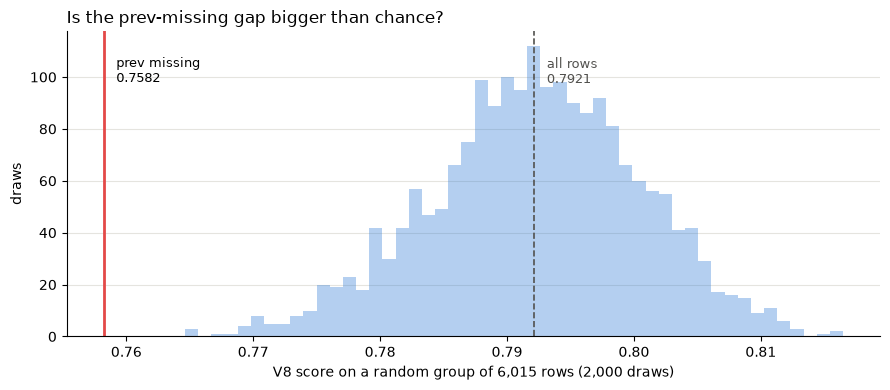

In [11]:
rng = np.random.default_rng(342)
n = int(prev_missing.sum())
null = np.array([_score(y.to_numpy()[i], pred.to_numpy()[i])
                 for i in (rng.choice(len(tr), n, replace=False) for _ in range(2000))])  # random groups of the same size
observed = focus.loc['prev missing', 'V8_score']
lo, hi = np.percentile(null, [2.5, 97.5])
print(f"random {n:,}-row groups: 95% of scores in [{lo:.4f}, {hi:.4f}] | prev-missing group {observed:.4f} | "
      f"random groups at or below it: {(null <= observed).mean():.2%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(null, bins=50, color='#2a78d6', alpha=0.35)
ax.axvline(observed, color='#e34948', linewidth=2)
ax.text(observed + 0.001, 0.92, f"prev missing\n{observed:.4f}", transform=ax.get_xaxis_transform(), fontsize=9, va='top')
ax.axvline(oof, color='#52514e', linestyle='--', linewidth=1.2)
ax.text(oof + 0.001, 0.92, f"all rows\n{oof:.4f}", transform=ax.get_xaxis_transform(), fontsize=9, va='top', color='#52514e')
ax.set_xlabel(f'V8 score on a random group of {n:,} rows (2,000 draws)')
ax.set_ylabel('draws')
ax.set_title('Is the prev-missing gap bigger than chance?', loc='left')
ax.grid(axis='y', color='#e5e4df', linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**NOTE:**

The targets look the same in both groups (zero share 48%, about 12–13% over 20k, similar medians), so the drop from 0.794 to 0.758 comes from the model, not from harder rows. The gap is real: none of the 2,000 random groups scored that low.

## 5. Can the missing values be imputed? (label-free)

ไม่มี feature ไหนผ่าน flag 1.5 เลยดู 3 ตัวที่ excess สูงสุดแทน (`prev_month_spending`, `historical_spending`, `avg_transaction_value`)

แต่ละตัว: เทรน HistGradientBoosting 3-fold บนแถวที่มีค่า ใช้ feature อื่นทั้งหมด (**ไม่ใช้** `spending_30d`) ทายค่า `log1p` ของ feature นั้น แล้ววัด R² (บน log และบนค่าจริง) และ Spearman ระหว่างค่าที่ทายกับค่าจริง feature ที่ช่วยทายวัดด้วย permutation importance (R² ที่หายไปเมื่อสลับค่า feature นั้น) บน 5,000 แถวของ fold สุดท้าย

In [12]:
candidates = by_feat.index[:3].tolist()
assert 'spending_30d' not in feats
impute_rows = []
for f in candidates:
    present = tr[f].notna()
    X = tr.loc[present, [c for c in feats if c != f]]  # the other 31 features only, never the target
    t = np.log1p(tr.loc[present, f])
    p = np.zeros(len(t))
    for a, b in KFold(3, shuffle=True, random_state=342).split(X):
        model = HistGradientBoostingRegressor(random_state=342).fit(X.iloc[a], t.iloc[a])
        p[b] = model.predict(X.iloc[b])
    pi = permutation_importance(model, X.iloc[b][:5000], t.iloc[b][:5000], n_repeats=3, random_state=342, scoring='r2')
    top = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False).head(3)
    impute_rows.append({'feature': f, 'rows used': len(t), 'R² (log1p)': r2_score(t, p),
                        'R² (THB)': r2_score(np.expm1(t), np.expm1(p)), 'Spearman': spearmanr(t, p)[0],
                        'top predictors (R² drop)': ', '.join(f"{k} {v:.2f}" for k, v in top.items())})
imputation = pd.DataFrame(impute_rows).set_index('feature')
(imputation.style
    .format({'rows used': '{:,}', 'R² (log1p)': '{:.3f}', 'R² (THB)': '{:.3f}', 'Spearman': '{:.3f}'})
    .set_caption('Label-free imputation, 3-fold out-of-fold, on rows where the feature is present'))

,rows used,R² (log1p),R² (THB),Spearman,top predictors (R² drop)
feature,,,,,
prev_month_spending,"97,985",0.995,0.984,0.997,"historical_spending 1.69, avg_transaction_value 0.14, total_transactions 0.02"
historical_spending,"97,965",0.995,0.987,0.997,"prev_month_spending 1.53, avg_transaction_value 0.14, segment 0.02"
avg_transaction_value,"98,009",0.996,0.925,0.998,"historical_spending 0.76, prev_month_spending 0.40, total_transactions 0.37"


In [13]:
both_missing = tr.loc[prev_missing, 'historical_spending'].isna().mean()
print(f"rows missing prev_month_spending that also miss historical_spending: {both_missing:.1%}")

rows missing prev_month_spending that also miss historical_spending: 6.1%


**NOTE:**

Imputation is easy: R² 0.995 on the log scale for all three. The spend-history features are almost copies of each other. `prev_month_spending` is predicted almost entirely by `historical_spending`, which is present in 94% of the rows where prev is missing.

So V8 already sees most of the missing information through `historical_spending`. What it loses is the ratio target: with prev = 1, it has to learn `log(y)` directly from about 6% of the training rows.

## 6. Upper bound: what if the prev-missing rows were as good as the rest? (oracle)

สมมติว่าแถวที่ `prev_month_spending` หายมี error rate เท่ากลุ่มที่มีค่า แล้วดูว่า error รวมลดลงเท่าไร และ OOF ขยับเท่าไร เป็นแค่ขอบบน การเติมค่าจริงไม่น่าทำได้ดีขนาดนี้

- **error per THB** (หลัก): error ของกลุ่ม = (error รวม / target รวม ของกลุ่มที่มีค่า) × target รวมของกลุ่มที่หาย ตรงกับวิธีคิดของ metric
- **mean |error| per row** (เช็ค): error ของกลุ่ม = |error| เฉลี่ยต่อแถวของกลุ่มที่มีค่า × จำนวนแถว

In [14]:
e_missing = err[prev_missing].sum()
oracle_errors = {
    'error per THB': err[~prev_missing].sum() / y[~prev_missing].sum() * y[prev_missing].sum(),
    'mean |error| per row': err[~prev_missing].mean() * prev_missing.sum(),
}
oracle = pd.DataFrame([{
    'rate used': name,
    'group error now (M THB)': e_missing / 1e6,
    'group error oracle (M THB)': e_new / 1e6,
    'total error drop': (e_missing - e_new) / E,
    'OOF now': oof,
    'OOF oracle': 1 / (1 + (E - e_missing + e_new) / Y),
} for name, e_new in oracle_errors.items()]).set_index('rate used')
oracle['OOF change'] = oracle['OOF oracle'] - oracle['OOF now']
(oracle.style
    .format({'group error now (M THB)': '{:.1f}', 'group error oracle (M THB)': '{:.1f}', 'total error drop': '{:.2%}',
             'OOF now': '{:.4f}', 'OOF oracle': '{:.4f}', 'OOF change': '{:+.4f}'})
    .set_caption('Oracle: prev-missing rows at the error rate of the prev-present rows'))

,group error now (M THB),group error oracle (M THB),total error drop,OOF now,OOF oracle,OOF change
rate used,,,,,,
error per THB,20.7,16.8,1.36%,0.7921,0.7944,+0.0022
mean |error| per row,20.7,16.3,1.54%,0.7921,0.7947,+0.0025


**NOTE:**

The upper bound is +0.0022 (+0.0025 using the per-row rate), just above the +0.002 bar. A real imputation would recover only part of it.

## Summary

- **V8 OOF:** ได้ 0.7921 ตรงกับ `champion.json` และแถวเรียงตรงกับ `train.csv` (เช็ค `player_id` แล้ว)
- **ค่าว่าง:** ทุก feature หาย 5.7–6.0% และ 85% ของแถวหายอย่างน้อยหนึ่งช่อง สัดส่วนคนใช้เงินเท่ากันทั้งแถวที่หายและแถวที่มีค่า (~52%)
- **Error ต่อ feature:** ไม่มี feature ไหนผ่าน flag 1.5 สูงสุดคือ `prev_month_spending` ที่ 1.25 (7.2% ของ error รวมบน 5.8% ของแถว, excess +1.45%) ตามด้วย `historical_spending` 1.15 และ `avg_transaction_value` 1.13 สามตัวบนเป็นประวัติการใช้จ่ายทั้งหมด
- **จำนวนช่องที่หายต่อแถว:** error เป็นสัดส่วนตามจำนวนแถว (ratio 0.95–1.05) ต่างจาก Task 1 ค่าว่างไม่ได้เป็นเพดานของงานนี้
- **`prev_month_spending` หาย:** target สองกลุ่มหน้าตาเหมือนกัน (เป็น 0 อยู่ 48%, เกิน 20k 12–13%) แต่ V8 ได้ 0.758 เทียบกับ 0.794 ช่องว่างนี้เป็นของจริง: คะแนนต่ำกว่ากลุ่มสุ่มขนาดเท่ากันทั้ง 2,000 ครั้ง (95% อยู่ในช่วง 0.775–0.808)
- **เติมค่าได้ง่าย:** R² (log) 0.995, Spearman 0.997 ทายจาก `historical_spending` เกือบทั้งหมด ซึ่งมีค่าใน 94% ของแถวที่ prev หาย สองตัวที่เหลือก็ได้ R² 0.995+ เหมือนกัน
- **Oracle:** ถ้าแถวที่ prev หายทายได้ดีเท่ากลุ่มที่มีค่า error รวมลด 1.4% และ OOF ขึ้นได้มากสุด +0.0022 (+0.0025 ถ้าคิด error ต่อแถว)

**Decision: หยุด Task 3, ใช้ V8 เป็นตัวสุดท้าย**

| เกณฑ์ | ผล | ผ่านไหม |
|---|---|---|
| error กองในแถวที่ flag (ratio > 1.5) | ไม่มี feature ถูก flag, สูงสุด 1.25 | ไม่ผ่าน |
| imputation R² > 0.3 | 0.995 (log1p) | ผ่าน |
| oracle > +0.002 OOF | +0.0022 | ผ่านแบบเฉียด |

ต้องผ่านครบทั้งสามข้อ และข้อแรกไม่ผ่าน ช่องว่างของแถวที่ prev หายเป็นของจริงแต่เล็ก (1.4% ของ error รวม) +0.0022 ก็เป็นแค่ขอบบนที่การเติมค่าจริงทำได้ไม่ถึง และ V8 ที่ชนะ V4 ใน CV ได้ขึ้นบน Kaggle public แค่ +0.00008 การเปลี่ยนแปลงของ OOF ต่ำกว่า 0.002 จึงไม่น่าจะเห็นบน leaderboard

**CAUTION:** If the team still wants one last try anyway, the cheapest V9 is: impute `prev_month_spending` label-free (HistGradientBoosting on the other features, fit inside each outer fold, train + test features allowed), use the imputed prev as the ratio denominator only for rows where it is missing, keep the `prev_missing` flag, and promote only if it beats V8 on all 3 folds under honest-es (the same rule as before).

**Follow-up: ลอง V9 ก่อนปิด Task 3** ตามกฎต้องหยุด เพราะไม่มี feature ไหนผ่าน flag 1.5 แต่ flag นี้ตั้งไว้ก่อนเห็นข้อมูล และเข้มเกินไปสำหรับงานนี้ ช่องว่างของแถวที่ `prev_month_spending` หายมีนัยสำคัญ (0.758 เทียบกับ 0.794 ไม่มีกลุ่มสุ่มไหนใน 2,000 ครั้งต่ำขนาดนั้น) target สองกลุ่มหน้าตาเหมือนกัน ช่องว่างจึงมาจากโมเดล การเติมค่าแทบสมบูรณ์ (R² 0.995) และแถวที่หาย 2 ช่องขึ้นไปได้ 0.786 เทียบกับ 0.799 ของแถวที่หาย 0–1 ช่อง เลยลองอีกหนึ่งการทดลองที่ไม่แพง: V9 เติมค่า feature ประวัติการใช้จ่ายแบบไม่ใช้ label (ตามโครงใน CAUTION ด้านบน)